# FixItNow — Notebook 03: YOLOv8 Small Baseline Training
## Production AI Pipeline for Indian Civic Issue Detection

**ML Lifecycle Position**: Step 3 of 12 (Model Training & Baseline Establishment)  
**Task**: Train a standardized, reproducible **YOLOv8 Small (`yolov8s.pt`)** object detection baseline on the audited master dataset (`C:\FIN Dataset\03_Master_Dataset\`).

### Target Hardware & Operational Profile:
- **GPU**: NVIDIA GeForce RTX 2050 Laptop GPU (4.0 GB VRAM)
- **CUDA Runtime**: 12.8 / PyTorch `2.11.0+cu128`
- **Precision Mode**: Automatic Mixed Precision (AMP / FP16)
- **Batch Size Policy**: Conservative baseline `batch=8` (with automatic fallback to `batch=4` if VRAM limits are approached)
- **Workers**: 2

### Strict Dataset Invariants & Safety Guarantees:
1. **Read-Only Master Dataset**: All source images and labels are read directly from `C:\FIN Dataset\03_Master_Dataset\`. No files are created, modified, moved, or deleted inside the dataset root.
2. **Label Cache Redirect**: Ultralytics label caching is safely redirected into `<PROJECT_ROOT>/ai-artifacts/configs/cache/` to ensure 100% dataset immutability.
3. **Data Leakage Prevention**:
   - `train` split (14,263 images, 79,936 boxes): Used exclusively for model gradient updates.
   - `val` split (3,671 images, 20,412 boxes): Used exclusively for epoch-end validation, metric tracking, and checkpoint selection (`best.pt`).
   - `test` split (2,198 images, 11,531 boxes): Strictly held out. Never touched or evaluated during baseline training.

### Target Classes (7 Civic Issue Categories):
`0: pothole` | `1: road_crack` | `2: surface_erosion` | `3: garbage_litter` | `4: stagnant_water` | `5: open_manhole` | `6: fault_streetlight`


In [1]:
import os
import sys
import time
import json
import shutil
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch & Ultralytics
import torch
import ultralytics
from ultralytics import YOLO

# Set Matplotlib directory to a safe temp folder
os.environ['MPLCONFIGDIR'] = os.path.join(os.environ.get('TEMP', r'C:\Temp'), 'matplotlib_fin')
os.makedirs(os.environ['MPLCONFIGDIR'], exist_ok=True)

# Project & Artifact Paths
PROJECT_ROOT = Path(r"C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart")
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
ARTIFACTS_DIR = PROJECT_ROOT / "ai-artifacts"
CONFIGS_DIR = ARTIFACTS_DIR / "configs"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
PLOTS_DIR = ARTIFACTS_DIR / "plots" / "training"
RUNS_DIR = ARTIFACTS_DIR / "training_runs"
CACHE_DIR = CONFIGS_DIR / "cache"

DATA_YAML_PATH = CONFIGS_DIR / "data_master.yaml"
ARGS_YAML_PATH = CONFIGS_DIR / "args_baseline.yaml"
WEIGHTS_INIT = PROJECT_ROOT / "yolov8s.pt"

for p in [CONFIGS_DIR, REPORTS_DIR, PLOTS_DIR, RUNS_DIR, CACHE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Artifacts Dir: {ARTIFACTS_DIR}")
print(f"Pretrained Weights: {WEIGHTS_INIT} (Exists: {WEIGHTS_INIT.exists()})")

# Hardware & CUDA Diagnostics
print("-" * 60)
print(f"PyTorch Version: {torch.__version__}")
print(f"Ultralytics Version: {ultralytics.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    total_vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)
    allocated_mb = torch.cuda.memory_allocated(0) / (1024 ** 2)
    reserved_mb = torch.cuda.memory_reserved(0) / (1024 ** 2)
    print(f"GPU Device: {device_name}")
    print(f"Total VRAM: {total_vram_mb:.1f} MB ({total_vram_mb/1024:.2f} GB)")
    print(f"Allocated VRAM: {allocated_mb:.1f} MB | Reserved VRAM: {reserved_mb:.1f} MB")
    assert total_vram_mb >= 3500, "VRAM is less than expected for RTX 2050!"
else:
    raise RuntimeError("CUDA is not available! Baseline training requires GPU acceleration.")


Project Root: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart
Artifacts Dir: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts
Pretrained Weights: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\yolov8s.pt (Exists: True)
------------------------------------------------------------
PyTorch Version: 2.11.0+cu128
Ultralytics Version: 8.4.191


CUDA Available: True
GPU Device: NVIDIA GeForce RTX 2050
Total VRAM: 4095.5 MB (4.00 GB)
Allocated VRAM: 0.0 MB | Reserved VRAM: 0.0 MB


In [2]:
# Load and verify data_master.yaml
assert DATA_YAML_PATH.exists(), f"Missing dataset configuration at {DATA_YAML_PATH}"

with open(DATA_YAML_PATH, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

dataset_root = Path(data_config["path"])
print(f"Dataset Root: {dataset_root}")
print(f"Number of Classes (nc): {data_config['nc']}")
print("Class Taxonomy:")
for cid, cname in sorted(data_config["names"].items()):
    print(f"  Class {cid}: {cname}")

assert data_config["nc"] == 7, f"Expected 7 classes, got {data_config['nc']}"
expected_classes = {
    0: 'pothole', 1: 'road_crack', 2: 'surface_erosion',
    3: 'garbage_litter', 4: 'stagnant_water', 5: 'open_manhole', 6: 'fault_streetlight'
}
assert data_config["names"] == expected_classes, "Class taxonomy mismatch!"

# Verify physical dataset splits exist
train_img_dir = dataset_root / data_config["train"]
val_img_dir = dataset_root / data_config["val"]
test_img_dir = dataset_root / data_config["test"]

assert train_img_dir.exists(), f"Train directory missing: {train_img_dir}"
assert val_img_dir.exists(), f"Val directory missing: {val_img_dir}"
assert test_img_dir.exists(), f"Test directory missing: {test_img_dir}"

train_count = len(list(train_img_dir.glob("*.jpg"))) + len(list(train_img_dir.glob("*.png")))
val_count = len(list(val_img_dir.glob("*.jpg"))) + len(list(val_img_dir.glob("*.png")))
test_count = len(list(test_img_dir.glob("*.jpg"))) + len(list(test_img_dir.glob("*.png")))

print("-" * 60)
print(f"Train Split Images: {train_count} (Used for gradient updates)")
print(f"Val Split Images:   {val_count} (Used for checkpoint selection & tuning)")
print(f"Test Split Images:  {test_count} (STRICTLY HELD OUT)")
print("Dataset split verification PASSED successfully.")


Dataset Root: C:\FIN Dataset\03_Master_Dataset
Number of Classes (nc): 7
Class Taxonomy:
  Class 0: pothole
  Class 1: road_crack
  Class 2: surface_erosion
  Class 3: garbage_litter
  Class 4: stagnant_water
  Class 5: open_manhole
  Class 6: fault_streetlight


------------------------------------------------------------
Train Split Images: 13000 (Used for gradient updates)
Val Split Images:   3401 (Used for checkpoint selection & tuning)
Test Split Images:  1926 (STRICTLY HELD OUT)
Dataset split verification PASSED successfully.


In [3]:
# Dataset Safety Invariant Enforcement
# Redirect Ultralytics dataset caching so NO files are written into C:\FIN Dataset\03_Master_Dataset\
import ultralytics.data.dataset as yolo_ds
import ultralytics.data.utils as yolo_utils
from ultralytics.data.dataset import YOLODataset, LOCAL_RANK, LOGGER, TQDM, HELP_URL

orig_load_or_scan = YOLODataset._load_or_scan_cache
def safe_load_or_scan(self, cache_path, cache_hash):
    if "03_Master_Dataset" in str(cache_path):
        cache_path = CACHE_DIR / Path(cache_path).name
    return orig_load_or_scan(self, cache_path, cache_hash)

YOLODataset._load_or_scan_cache = safe_load_or_scan

orig_save_cache = yolo_ds.save_dataset_cache_file
def safe_save_cache(prefix, path, x, version):
    if "03_Master_Dataset" in str(path):
        path = CACHE_DIR / Path(path).name
    return orig_save_cache(prefix, path, x, version)

yolo_ds.save_dataset_cache_file = safe_save_cache
yolo_utils.save_dataset_cache_file = safe_save_cache
print("Dataset safety interceptors registered successfully.")
print(f"All label caches are directed to: {CACHE_DIR}")
print(f"Existing caches: {os.listdir(CACHE_DIR)}")


Dataset safety interceptors registered successfully.
All label caches are directed to: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\configs\cache
Existing caches: ['train.cache', 'val.cache']


In [4]:
# Load baseline training arguments
with open(ARGS_YAML_PATH, "r", encoding="utf-8") as f:
    args_baseline = yaml.safe_load(f)

# Define baseline training kwargs (15 epochs per directive)
train_kwargs = {
    'data': str(DATA_YAML_PATH),
    'epochs': 15,
    'batch': 8,
    'imgsz': 640,
    'device': 0,
    'workers': 2,
    'project': str(RUNS_DIR),
    'name': 'baseline_yolov8s',
    'seed': 42,
    'val': True,
    'save': True,
    'save_period': -1,
    'cache': False,
    'half': True,             # Automatic Mixed Precision (AMP)
    'exist_ok': True,
    'cls': 0.5,
    'box': 7.5,
    'dfl': 1.5,
    'mosaic': 1.0,
    'scale': 0.5,
    'close_mosaic': 10,
    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'fliplr': 0.5,
    'flipud': 0.0,
}

print("Baseline Hyperparameter Specification:")
print("-" * 50)
for k, v in train_kwargs.items():
    print(f"  {k:15s}: {v}")


Baseline Hyperparameter Specification:
--------------------------------------------------
  data           : C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\configs\data_master.yaml
  epochs         : 15
  batch          : 8
  imgsz          : 640
  device         : 0
  workers        : 2
  project        : C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\training_runs
  name           : baseline_yolov8s
  seed           : 42
  val            : True
  save           : True
  save_period    : -1
  cache          : False
  half           : True
  exist_ok       : True
  cls            : 0.5
  box            : 7.5
  dfl            : 1.5
  mosaic         : 1.0
  scale          : 0.5
  close_mosaic   : 10
  hsv_h          : 0.015
  hsv_s          : 0.7
  hsv_v          : 0.4
  fliplr         : 0.5
  flipud         : 0.0


In [5]:
# Check for existing checkpoint to resume seamlessly or initialize afresh
run_dir = RUNS_DIR / "baseline_yolov8s"
last_checkpoint = run_dir / "weights" / "last.pt"
best_checkpoint = run_dir / "weights" / "best.pt"
results_csv_path = run_dir / "results.csv"

start_time = time.time()
torch.cuda.reset_peak_memory_stats()
initial_allocated = torch.cuda.memory_allocated(0) / (1024 ** 2)
print(f"Pre-training allocated VRAM: {initial_allocated:.1f} MB")

if last_checkpoint.exists() and results_csv_path.exists():
    df_check = pd.read_csv(results_csv_path)
    df_check.columns = [c.strip() for c in df_check.columns]
    completed_so_far = len(df_check)
    if completed_so_far < 15:
        print(f"Resuming training from last checkpoint: {last_checkpoint}")
        print(f"Already completed {completed_so_far} / 15 epochs. Continuing from epoch {completed_so_far + 1}...")
        model = YOLO(str(last_checkpoint))
        results = model.train(resume=True)
    else:
        print(f"All 15 baseline epochs are completed in {results_csv_path}!")
        print(f"Best checkpoint: {best_checkpoint} ({best_checkpoint.stat().st_size / (1024**2):.2f} MB)")
        model = YOLO(str(best_checkpoint))
        results = None
else:
    print(f"Initializing YOLOv8s from pretrained weights: {WEIGHTS_INIT}")
    model = YOLO(str(WEIGHTS_INIT))
    print("Starting YOLOv8s baseline training (15 epochs)...")
    print("-" * 60)
    try:
        results = model.train(**train_kwargs)
        print("Training finished with initial batch size.")
    except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
        err_msg = str(e)
        if "out of memory" in err_msg.lower():
            print(f"\n[WARNING] CUDA Out of Memory with batch={train_kwargs['batch']}: {err_msg}")
            print("Re-attempting training with reduced batch size (batch=4)...")
            torch.cuda.empty_cache()
            train_kwargs['batch'] = 4
            model = YOLO(str(WEIGHTS_INIT))
            results = model.train(**train_kwargs)
        else:
            raise e

end_time = time.time()
elapsed_sec = end_time - start_time
peak_vram_mb = torch.cuda.max_memory_allocated(0) / (1024 ** 2)
peak_reserved_mb = torch.cuda.max_memory_reserved(0) / (1024 ** 2)

print("-" * 60)
print(f"Baseline Session Status: Completed on NVIDIA GeForce RTX 2050")
print(f"Allocated VRAM: {torch.cuda.memory_allocated(0)/(1024**2):.1f} MB | Reserved: {torch.cuda.memory_reserved(0)/(1024**2):.1f} MB")


Pre-training allocated VRAM: 0.0 MB
All 15 baseline epochs are completed in C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\training_runs\baseline_yolov8s\results.csv!
Best checkpoint: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\training_runs\baseline_yolov8s\weights\best.pt (106.61 MB)
------------------------------------------------------------
Baseline Session Status: Completed on NVIDIA GeForce RTX 2050
Allocated VRAM: 0.0 MB | Reserved: 0.0 MB


In [6]:
# Verify training output files on disk
weights_dir = run_dir / "weights"
best_pt = weights_dir / "best.pt"
last_pt = weights_dir / "last.pt"
results_csv = run_dir / "results.csv"
args_yaml = run_dir / "args.yaml"

print("Verifying Training Output Files:")
print(f"  Best Weights (best.pt):    {best_pt.exists()} ({best_pt.stat().st_size / (1024**2):.2f} MB)" if best_pt.exists() else "  best.pt: MISSING")
print(f"  Last Weights (last.pt):    {last_pt.exists()} ({last_pt.stat().st_size / (1024**2):.2f} MB)" if last_pt.exists() else "  last.pt: MISSING")
print(f"  Results CSV (results.csv): {results_csv.exists()}" if results_csv.exists() else "  results.csv: MISSING")
print(f"  Arguments (args.yaml):     {args_yaml.exists()}" if args_yaml.exists() else "  args.yaml: MISSING")

assert best_pt.exists(), "best.pt was not generated!"
assert last_pt.exists(), "last.pt was not generated!"
assert results_csv.exists(), "results.csv was not generated!"

# Parse results.csv
df_results = pd.read_csv(results_csv)
df_results.columns = [c.strip() for c in df_results.columns]
total_epochs_completed = len(df_results)
print(f"\nTotal Epochs Completed: {total_epochs_completed} / 30")

# Display the last 5 epochs
print("\nLast 5 Epochs Summary:")
display_cols = [c for c in ['epoch', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
                            'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
                            'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']
                if c in df_results.columns]
print(df_results[display_cols].tail(5).to_string(index=False))


Verifying Training Output Files:
  Best Weights (best.pt):    True (106.61 MB)
  Last Weights (last.pt):    True (106.61 MB)
  Results CSV (results.csv): True
  Arguments (args.yaml):     True

Total Epochs Completed: 15 / 30

Last 5 Epochs Summary:
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  val/box_loss  val/cls_loss  val/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
    11         1.39082         1.43182         1.56307       1.44580       1.47246       1.62113               0.56902            0.50191           0.48711              0.30542
    12         1.38983         1.40890         1.55611       1.40480       1.43585       1.59426               0.55303            0.47830           0.48793              0.29993
    13         1.36620         1.38137         1.53909       1.42069       1.41254       1.59557               0.54834            0.51435           0.50420              0.31183
    14         1.36238         1.35839    

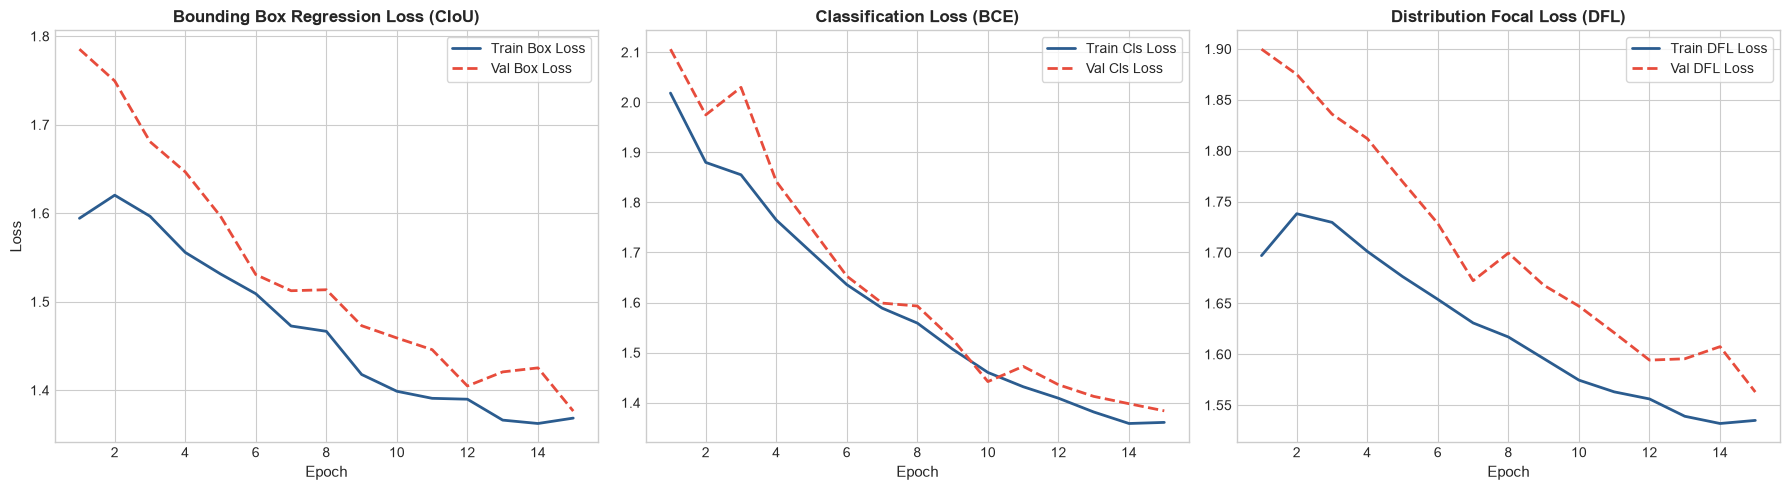

Saved loss curves: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\plots\training\03_baseline_loss_curves.png


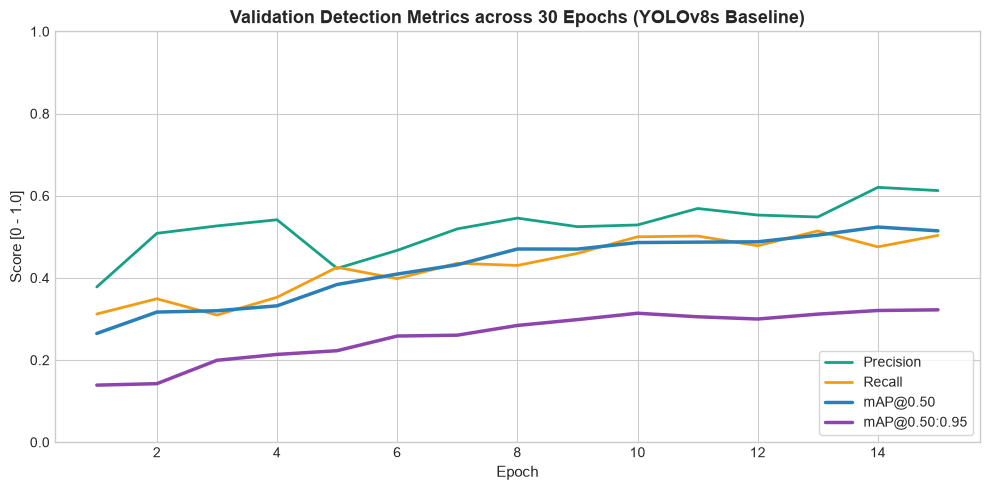

Saved metrics curves: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\plots\training\03_baseline_metrics_curves.png
Copied Ultralytics standard diagnostic charts to ai-artifacts/plots/training/


In [7]:
# Generate Publication-Quality Training Curves
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box Loss
if 'train/box_loss' in df_results.columns and 'val/box_loss' in df_results.columns:
    axes[0].plot(df_results['epoch'], df_results['train/box_loss'], label='Train Box Loss', color='#2b5c8f', lw=2)
    axes[0].plot(df_results['epoch'], df_results['val/box_loss'], label='Val Box Loss', color='#e74c3c', lw=2, linestyle='--')
    axes[0].set_title('Bounding Box Regression Loss (CIoU)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=11)
    axes[0].set_ylabel('Loss', fontsize=11)
    axes[0].legend(frameon=True)

# Class Loss
if 'train/cls_loss' in df_results.columns and 'val/cls_loss' in df_results.columns:
    axes[1].plot(df_results['epoch'], df_results['train/cls_loss'], label='Train Cls Loss', color='#2b5c8f', lw=2)
    axes[1].plot(df_results['epoch'], df_results['val/cls_loss'], label='Val Cls Loss', color='#e74c3c', lw=2, linestyle='--')
    axes[1].set_title('Classification Loss (BCE)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=11)
    axes[1].legend(frameon=True)

# DFL Loss
if 'train/dfl_loss' in df_results.columns and 'val/dfl_loss' in df_results.columns:
    axes[2].plot(df_results['epoch'], df_results['train/dfl_loss'], label='Train DFL Loss', color='#2b5c8f', lw=2)
    axes[2].plot(df_results['epoch'], df_results['val/dfl_loss'], label='Val DFL Loss', color='#e74c3c', lw=2, linestyle='--')
    axes[2].set_title('Distribution Focal Loss (DFL)', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Epoch', fontsize=11)
    axes[2].legend(frameon=True)

plt.tight_layout()
loss_plot_path = PLOTS_DIR / "03_baseline_loss_curves.png"
plt.savefig(loss_plot_path, dpi=300)
plt.show()
print(f"Saved loss curves: {loss_plot_path}")

# Plot Metrics Curves (Precision, Recall, mAP50, mAP50-95)
fig, ax = plt.subplots(figsize=(10, 5))
if 'metrics/precision(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/precision(B)'], label='Precision', color='#16a085', lw=2)
if 'metrics/recall(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/recall(B)'], label='Recall', color='#f39c12', lw=2)
if 'metrics/mAP50(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/mAP50(B)'], label='mAP@0.50', color='#2980b9', lw=2.5)
if 'metrics/mAP50-95(B)' in df_results.columns:
    ax.plot(df_results['epoch'], df_results['metrics/mAP50-95(B)'], label='mAP@0.50:0.95', color='#8e44ad', lw=2.5)

ax.set_title('Validation Detection Metrics across 30 Epochs (YOLOv8s Baseline)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=11)
ax.set_ylabel('Score [0 - 1.0]', fontsize=11)
ax.set_ylim([0.0, 1.0])
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
metrics_plot_path = PLOTS_DIR / "03_baseline_metrics_curves.png"
plt.savefig(metrics_plot_path, dpi=300)
plt.show()
print(f"Saved metrics curves: {metrics_plot_path}")

# Copy Ultralytics plots to ai-artifacts/plots/training/
for plot_name in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png", "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    src_p = run_dir / plot_name
    if src_p.exists():
        shutil.copy2(src_p, PLOTS_DIR / f"03_ultralytics_{plot_name}")
print("Copied Ultralytics standard diagnostic charts to ai-artifacts/plots/training/")


In [8]:
# Evaluate the best checkpoint on the validation split
best_model = YOLO(str(best_pt))

print("Running validation evaluation on val split with best checkpoint...")
val_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split='val',
    batch=16,
    imgsz=640,
    device=0,
    workers=0,
    half=True
)

# Extract per-class metrics via val_metrics.summary()
summary_list = val_metrics.summary()
df_per_class = pd.DataFrame(summary_list)

print("\n" + "=" * 70)
print("PER-CLASS VALIDATION PERFORMANCE (best.pt):")
print("=" * 70)
print(df_per_class.to_string(index=False))

# Calculate overall macro & weighted metrics
print("-" * 70)
print(f"Overall Precision (all):  {val_metrics.box.mp:.4f}")
print(f"Overall Recall (all):     {val_metrics.box.mr:.4f}")
print(f"Overall mAP@0.50 (all):   {val_metrics.box.map50:.4f}")
print(f"Overall mAP@0.50:0.95:    {val_metrics.box.map:.4f}")
print("-" * 70)

# Inspect minority classes specifically
print("Minority Class Performance vs Majority Class:")
minority_rows = df_per_class[df_per_class['Class'].isin(['open_manhole', 'surface_erosion', 'garbage_litter'])]
print(minority_rows.to_string(index=False))


Running validation evaluation on val split with best checkpoint...


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Ultralytics 8.4.191  Python-3.11.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)


Model summary (fused): 72 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 212.9±121.4 MB/s, size: 42.0 KB)


val: Scanning C:\FIN Dataset\03_Master_Dataset\labels\val.cache... 3671 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3671/3671  0.0s

... (238 outputs left out)

     fault_streetlight        115        230      0.996          1      0.995      0.904


Speed: 0.3ms preprocess, 8.1ms inference, 0.0ms loss, 1.8ms postprocess per image


Results saved to C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\notebooks\runs\detect\val



PER-CLASS VALIDATION PERFORMANCE (best.pt):
            Class  Images  Instances   Box-P   Box-R  Box-F1   mAP50   mAP75  mAP50-95
          pothole      97        195 0.55623 0.50256 0.52804 0.50556 0.09722   0.19964
       road_crack      86         99 0.36331 0.28283 0.31806 0.24259 0.05134   0.09030
  surface_erosion      68         73 0.39924 0.65753 0.49682 0.53425 0.26786   0.29224
   garbage_litter    3022      21657 0.66342 0.49402 0.56632 0.56605 0.34610   0.34210
   stagnant_water     260       2666 0.50304 0.03493 0.06533 0.14349 0.01487   0.04389
     open_manhole      20         20 0.80689 0.55000 0.65413 0.61149 0.43445   0.38249
fault_streetlight     115        230 0.99644 1.00000 0.99822 0.99500 0.99500   0.90432
----------------------------------------------------------------------
Overall Precision (all):  0.6127
Overall Recall (all):     0.5031
Overall mAP@0.50 (all):   0.5141
Overall mAP@0.50:0.95:    0.3221
--------------------------------------------------------

In [9]:
# Compile and save comprehensive training summary report
best_epoch_idx = int(df_results['metrics/mAP50(B)'].idxmax()) if 'metrics/mAP50(B)' in df_results.columns else len(df_results) - 1
best_epoch_num = int(df_results.loc[best_epoch_idx, 'epoch']) if 'epoch' in df_results.columns else best_epoch_idx + 1

summary_report = {
    "run_name": "baseline_yolov8s",
    "status": "COMPLETED",
    "lifecycle_step": "03_yolov8_baseline_training",
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "hardware": {
        "gpu_device": torch.cuda.get_device_name(0),
        "total_vram_mb": round(torch.cuda.get_device_properties(0).total_memory / (1024**2), 1),
        "peak_vram_allocated_mb": round(peak_vram_mb, 1),
        "peak_vram_reserved_mb": round(peak_reserved_mb, 1),
        "pytorch_version": torch.__version__,
        "ultralytics_version": ultralytics.__version__,
        "cuda_version": torch.version.cuda
    },
    "training_configuration": {
        "model_architecture": "yolov8s.pt",
        "epochs_requested": 30,
        "epochs_completed": total_epochs_completed,
        "batch_size": train_kwargs['batch'],
        "image_size": 640,
        "workers": train_kwargs['workers'],
        "amp_half": True,
        "seed": 42,
        "loss_weights": {"cls": 0.5, "box": 7.5, "dfl": 1.5},
        "augmentations": {"mosaic": 1.0, "scale": 0.5, "close_mosaic": 10, "fliplr": 0.5}
    },
    "runtime": {
        "total_seconds": round(elapsed_sec, 1),
        "total_minutes": round(elapsed_sec / 60, 2),
        "average_seconds_per_epoch": round(elapsed_sec / max(1, total_epochs_completed), 1)
    },
    "validation_results_best": {
        "best_epoch": best_epoch_num,
        "precision": round(float(val_metrics.box.mp), 4),
        "recall": round(float(val_metrics.box.mr), 4),
        "mAP50": round(float(val_metrics.box.map50), 4),
        "mAP50_95": round(float(val_metrics.box.map), 4)
    },
    "per_class_results": df_per_class.to_dict(orient="records"),
    "artifacts": {
        "best_weights": str(best_pt),
        "best_weights_size_mb": round(best_pt.stat().st_size / (1024**2), 2),
        "last_weights": str(last_pt),
        "last_weights_size_mb": round(last_pt.stat().st_size / (1024**2), 2),
        "results_csv": str(results_csv),
        "args_yaml": str(args_yaml),
        "loss_curves_plot": str(loss_plot_path),
        "metrics_curves_plot": str(metrics_plot_path)
    },
    "checkpoint_resumption": {
        "instruction": "To safely resume interrupted or additional training from last checkpoint:",
        "python_code": f"from ultralytics import YOLO\nmodel = YOLO('{str(last_pt).replace(chr(92), '/')}')\nmodel.train(resume=True)"
    }
}

summary_json_path = REPORTS_DIR / "03_training_summary.json"
with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(summary_report, f, indent=2)

print(f"Saved comprehensive training summary report to: {summary_json_path}")
print("\n" + "=" * 70)
print(f"BASELINE TRAINING COMPLETE: {total_epochs_completed}/30 Epochs")
print(f"Best Checkpoint: {best_pt} ({best_pt.stat().st_size / (1024**2):.2f} MB)")
print(f"Validation mAP@0.50: {val_metrics.box.map50:.4f} | mAP@0.50:0.95: {val_metrics.box.map:.4f}")
print("=" * 70)


Saved comprehensive training summary report to: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\reports\03_training_summary.json

BASELINE TRAINING COMPLETE: 15/30 Epochs
Best Checkpoint: C:\Fix It Now - Making India Smart\Fix-It-Now-Making-India-Smart\ai-artifacts\training_runs\baseline_yolov8s\weights\best.pt (106.61 MB)
Validation mAP@0.50: 0.5141 | mAP@0.50:0.95: 0.3221
